# IRWA Project — Part 1
Text processing, indexing and exploratory data analysis of the Flipkart fashion corpus.

Run all cells in order. The dataset is located automatically from the repository root
or from this notebook's directory; If dependencies are missing in another kernel,
install `project_progress/part_1/requirements-notebook.txt` with `%pip install -r` first.
All figures are displayed inline and retained in the saved notebook.

## Part 1: Data preparation
### Load the local dataset

In [ ]:
#Added because we work with Python3.8
from __future__ import annotations

import json
import os
from pathlib import Path

import certifi

# Python.org installations on macOS may need an explicit, verified CA bundle.
os.environ.setdefault("SSL_CERT_FILE", certifi.where())

dataset_relative_path = Path("data/fashion_products_dataset.json")
project_root = next(
    (directory for directory in (Path.cwd(), *Path.cwd().parents)
     if (directory / dataset_relative_path).is_file()),
    None,
)
if project_root is None:
    raise FileNotFoundError(
        "Run this notebook from inside irwa-search-engine, with "
        "data/fashion_products_dataset.json available."
    )
docs_path = project_root / dataset_relative_path
print(f"Dataset: {docs_path}")

Dataset: /Users/joanvm/Desktop/Curso 26-27/Primer Trimestre/RIAW/irwa-search-engine/data/fashion_products_dataset.json


In [2]:
class Product:
  def __init__(self, _id, actual_price, average_rating, brand, category, crawled_at, description, discount, images, out_of_stock, pid, product_details, seller, selling_price, sub_category, title, url):
    self._id = _id
    self.actual_price = actual_price
    self.average_rating = average_rating
    self.brand = brand
    self.category = category
    self.crawled_at = crawled_at
    self.description = description
    self.discount = discount
    self.images = images
    self.out_of_stock = out_of_stock
    self.pid = pid
    self.product_details = product_details
    self.seller = seller
    self.selling_price = selling_price
    self.sub_category = sub_category
    self.title = title
    self.url = url

In [3]:
with docs_path.open(encoding="utf-8") as fp:
    raw_products = json.load(fp)

products = [Product(**record) for record in raw_products]
products_by_pid = {product.pid: product for product in products}
print(f"Loaded {len(products):,} products; {len(products_by_pid):,} unique product IDs.")

Loaded 28,080 products; 28,080 unique product IDs.


### Text processing and positional indexes


In [4]:
import nltk
from nltk.stem import PorterStemmer
from nltk.corpus import stopwords
from collections import Counter, defaultdict
from functools import lru_cache

for resource, package in (
    ("corpora/stopwords", "stopwords"),
    ("tokenizers/punkt_tab/english", "punkt_tab"),
):
    try:
        nltk.data.find(resource)
    except LookupError:
        nltk.download(package, quiet=True, raise_on_error=True)

stop_words = set(stopwords.words("english"))
stemmer = PorterStemmer()

@lru_cache(maxsize=100_000)
def stem_term(word):
    return stemmer.stem(word)

In [5]:
split_chars = '/.,-'

def split_joined_words(text):
  chars = list(text)
  for i, ch in enumerate(text):
    if ch in split_chars:
      prev_is_letter = i > 0 and text[i - 1].isalpha()
      next_is_letter = i < len(text) - 1 and text[i + 1].isalpha()
      if prev_is_letter or next_is_letter:
        chars[i] = ' '
  return ''.join(chars)

def merge_tshirt(words):
    result = []
    i = 0
    while i < len(words):
        if words[i] == 't' and i + 1 < len(words) and words[i + 1] in ('shirt', 'shirts'):
            result.append('tshirt')
            i += 2
        else:
            result.append('tshirt' if words[i] == 'tshirts' else words[i])
            i += 1
    return result

def build_terms(text: str):
    text = split_joined_words(text.lower())
    words = merge_tshirt(text.split())       # BEFORE stop words: "t" is an nltk stop word
    words = [w for w in words if w not in stop_words]
    words = [''.join(ch for ch in w if ch.isalnum() or ch in '/%.') for w in words]
    words = [w.strip('./') for w in words]
    words = [w for w in words if w and w not in stop_words]
    return [stem_term(w) for w in words]

In [6]:
def get_product_index(terms, pid):
  index = {}

  for position, term in enumerate(terms):
      try:
          index[term][1].append(position)
      except KeyError:
          index[term] = [pid, [position]]
  return index

### Product-details cleaning
Index only selected attribute values. Drop empty values (`NA`, `N/A`,
`None`, or actual nulls), numeric-only values and negated attributes.
Boolean `Yes` values become their attribute name; `No` contributes nothing.
Normalize equivalent fit labels (for example, `Slim Fit` to `slim`),
split comma-separated lists and remove duplicates after normalization.

In [7]:
def preprocess_details(details):
    keep = {
        'fabric', 'pattern', 'sleeve', 'sleeve type', 'type', 'generic name',
        'ideal for', 'fit', 'brand fit', 'color', 'brand color', 'secondary color',
        'shade', 'neck type', 'neck', 'collar', 'occasion', 'closure', 'fly',
        'top closure', 'hooded', 'reversible', 'stretchable', 'rise', 'hem',
        'faded', 'distressed', 'length type', 'pocket type', 'pockets',
        'waistband', 'character', 'fabric details', 'knit type', 'weave type',
        'material', 'outer material', 'sole material', 'lining', 'lining material',
        'top fabric', 'bottom fabric', 'top type', 'bottom type', 'coat type',
        'upper pattern',
    }
    boolean_fields = {'hooded', 'reversible', 'stretchable'}
    missing_values = {
        '', 'na', 'n/a', 'n.a.', 'none', 'null', 'nan', '-', '--',
        'not available', 'not applicable',
    }
    fit_aliases = {
        'slim fit': 'slim',
        'regular fit': 'regular',
        'skinny fit': 'skinny',
        'loose fit': 'loose',
        'relaxed fit': 'relaxed',
        'comfort fit': 'comfort',
        'tailored fit': 'tailored',
        'super slim fit': 'super slim',
    }
    product_values = []
    seen_values = set()
    for detail in details or []:
        for key, value in detail.items():
            key = ' '.join(str(key).lower().split())
            if key not in keep or value is None:
                continue
            for part in str(value).split(','):
                part = ' '.join(part.lower().split())
                if part in missing_values:
                    continue
                if key in boolean_fields:
                    if part != 'yes':
                        continue
                    part = key
                elif part.isdigit() or part == 'no' or part.startswith(('no ', 'not ')):
                    continue
                elif key in {'fit', 'brand fit'}:
                    part = fit_aliases.get(part, part)
                if part not in seen_values:
                    seen_values.add(part)
                    product_values.append(part)
    return product_values

In [8]:
def create_indexes(products: list[Product]):
  text_index = defaultdict(list)
  detail_index = defaultdict(list)

  for product in products:

    text_terms = build_terms(product.title + " " + product.description)

    for term, term_info in get_product_index(text_terms, product.pid).items():
      text_index[term].append(term_info)


    current_detail_index = preprocess_details(product.product_details)
    detail_terms = build_terms(' '.join(current_detail_index))

    for term, term_info in get_product_index(detail_terms, product.pid).items():
      detail_index[term].append(term_info)

  return text_index, detail_index

In [9]:
text_index, detail_index = create_indexes(products)
print(f"Text index: {len(text_index):,} terms")
print(f"Product-details index: {len(detail_index):,} terms")

Text index: 5,288 terms
Product-details index: 1,381 terms


### Reproducible index example
Change `search_query` to try another word. This replaces the blocking `input()` so
**Run All** can complete without user interaction. Only the first five postings are shown.

In [10]:
search_query = "cotton"
query_terms = build_terms(search_query)
for term in query_terms:
    print(f"\nQuery term: {term}")
    for label, index in (("text", text_index), ("details", detail_index)):
        postings = index.get(term, [])
        print(f"{label}: {len(postings):,} products; first five [pid, positions]:")
        print(postings[:5])


Query term: cotton
text: 8,304 products; first five [pid, positions]:
[['TKPFCZ9EA7H5FYZH', [11]], ['TKPFCZ9EJZV2UVRZ', [11]], ['TKPFCZ9EHFCY5Z4Y', [11]], ['TKPFCZ9ESZZ7YWEF', [11]], ['TKPFCZ9EVXKBSUD7', [12]]]
details: 18,332 products; first five [pid, positions]:
[['TKPFCZ9EA7H5FYZH', [3]], ['TKPFCZ9EJZV2UVRZ', [4]], ['TKPFCZ9EHFCY5Z4Y', [3]], ['TKPFCZ9ESZZ7YWEF', [3]], ['TKPFCZ9EVXKBSUD7', [4]]]


### Numeric metadata for future search
We preserve original product fields for display. Store numeric prices, discounts
and ratings separately by `pid`, with missing values represented as `None`.
We decided to prepare `quality_score = rating / 5`.
We keep `out_of_stock` as a boolean for future filtering or ranking adjustments.

In [11]:
import math

def parse_numeric(value):
    if value is None:
        return None
    cleaned = str(value).replace(",", "").replace("% off", "").strip()
    try:
        number = float(cleaned)
    except (TypeError, ValueError):
        return None
    return number if math.isfinite(number) else None

numeric_field_names = ("average_rating", "selling_price", "actual_price", "discount")
numeric_fields_by_pid = {
    product.pid: {
        field: parse_numeric(getattr(product, field))
        for field in numeric_field_names
    }
    for product in products
}
available_ratings = [metadata["average_rating"]
                     for metadata in numeric_fields_by_pid.values()
                     if metadata["average_rating"] is not None]
mean_rating = sum(available_ratings) / len(available_ratings) if available_ratings else None
for product in products:
    metadata = numeric_fields_by_pid[product.pid]
    rating = metadata["average_rating"]
    rating_for_quality = rating if rating is not None else mean_rating
    metadata["quality_score"] = rating_for_quality / 5 if rating_for_quality is not None else None
    metadata["out_of_stock"] = product.out_of_stock

## Part 2: Exploratory Data Analysis
This section focuses on the analyses explicitly mentioned in the assignment:
word-count distributions, average sentence length, vocabulary size,
frequent words and word clouds, ratings, prices, discounts, top brands
and sellers, and stock distribution.

### 2.1 Text


In [12]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from wordcloud import WordCloud

%matplotlib inline
plt.rcParams.update({
    "figure.figsize": (10, 5),
    "figure.dpi": 110,
    "font.size": 11,
    "axes.titlesize": 14,
    "axes.spines.top": False,
    "axes.spines.right": False,
})

df = pd.DataFrame(raw_products)

def eda_tokens(text):
    return re.findall(r"\b\w+\b", str(text).lower())

title_tokens = [eda_tokens(text) for text in df["title"]]
description_tokens = [eda_tokens(text) for text in df["description"]]
document_tokens = [title + description
                   for title, description in zip(title_tokens, description_tokens)]
title_lengths = np.array([len(tokens) for tokens in title_tokens])
description_lengths = np.array([len(tokens) for tokens in description_tokens])
word_counts = Counter(word for tokens in document_tokens for word in tokens)
content_word_counts = Counter({word: count for word, count in word_counts.items()
                              if word not in stop_words})

description_sentences = [nltk.sent_tokenize(text) if text.strip() else []
                         for text in df["description"]]
sentence_count = sum(len(sentences) for sentences in description_sentences)
sentence_word_count = sum(len(eda_tokens(sentence))
                          for sentences in description_sentences for sentence in sentences)
text_summary = pd.DataFrame([
    ("Words per title (mean / max)", f"{title_lengths.mean():.1f} / {title_lengths.max():,}"),
    ("Words per description (mean / median / max)",
     f"{description_lengths.mean():.1f} / {np.median(description_lengths):.0f} / {description_lengths.max():,}"),
    ("Words per sentence", f"{sentence_word_count / sentence_count:.1f}"),
    ("Vocabulary size", f"{len(word_counts):,}"),
], columns=["Measure", "Value"]).set_index("Measure")
display(text_summary)

,Value
Measure,
Words per title (mean / max),6.9 / 36
Words per description (mean / median / max),30.7 / 11 / 693
Words per sentence,16.2
Vocabulary size,"6,541"


#### Description length


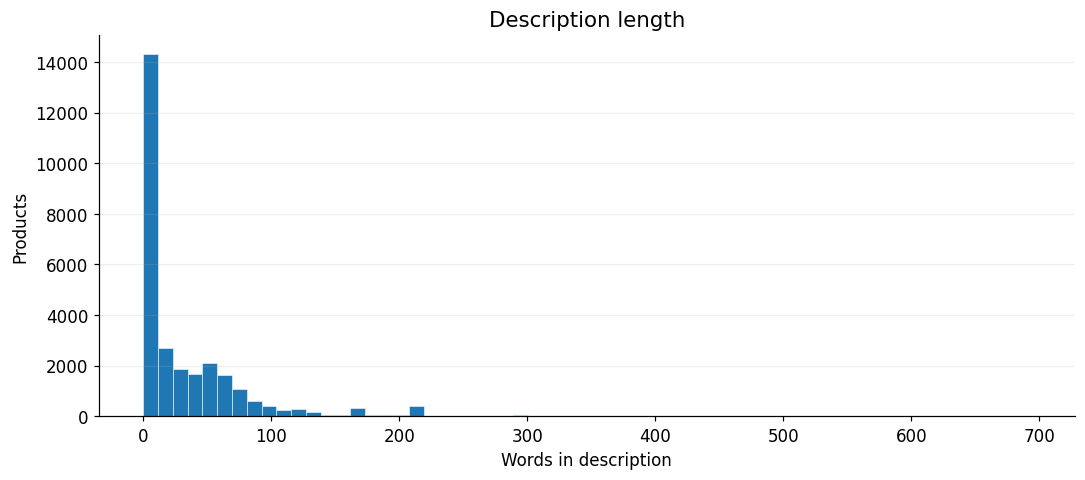

In [13]:
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.hist(description_lengths, bins=60, color="tab:blue", edgecolor="white", linewidth=0.35)
ax.set(title="Description length", xlabel="Words in description", ylabel="Products")
ax.grid(axis="y", alpha=0.2)
fig.tight_layout()
plt.show()

#### Most frequent words and word cloud


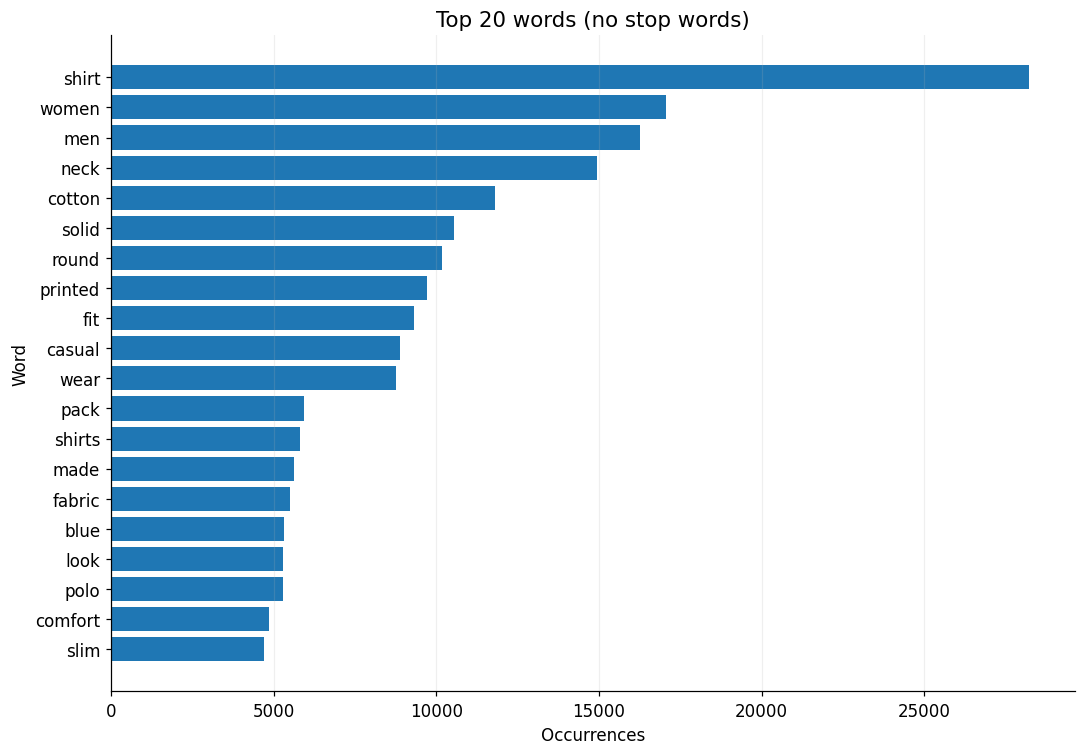

In [14]:
top_words = pd.Series(dict(content_word_counts.most_common(20)))
fig, ax = plt.subplots(figsize=(10, 7))
ax.barh(top_words.index[::-1], top_words.values[::-1], color="tab:blue")
ax.set(title="Top 20 words (no stop words)", xlabel="Occurrences", ylabel="Word")
ax.grid(axis="x", alpha=0.2)
fig.tight_layout()
plt.show()

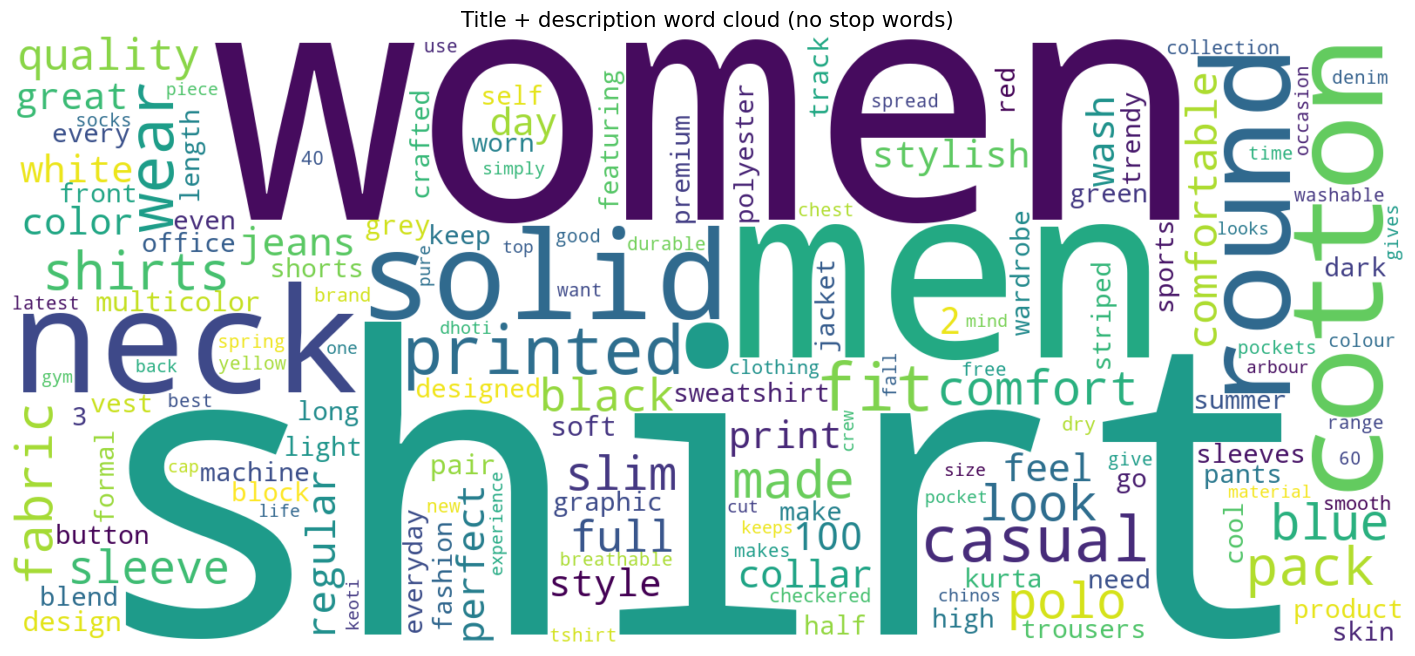

In [15]:
cloud = WordCloud(
    width=1600, height=700, background_color="white", max_words=150,
    random_state=42, collocations=False, colormap="viridis",
).generate_from_frequencies(content_word_counts)

fig, ax = plt.subplots(figsize=(13, 6))
ax.imshow(cloud, interpolation="bilinear")
ax.set_title("Title + description word cloud (no stop words)")
ax.axis("off")
fig.tight_layout()
plt.show()

### 2.2 Products


In [16]:
numeric_columns = ["average_rating", "selling_price", "actual_price", "discount"]
for column in numeric_columns:
    df[column] = [numeric_fields_by_pid[pid][column] for pid in df["pid"]]

numeric_summary = df[numeric_columns].agg(["mean", "median", "min", "max"]).T
numeric_summary.index.name = "Field"
display(numeric_summary.round(2))

,mean,median,min,max
Field,,,,
average_rating,3.63,3.8,1.0,5.0
selling_price,705.64,545.0,99.0,7999.0
actual_price,1455.53,1199.0,150.0,12999.0
discount,50.26,53.0,1.0,87.0


#### Rating, selling-price and discount distributions


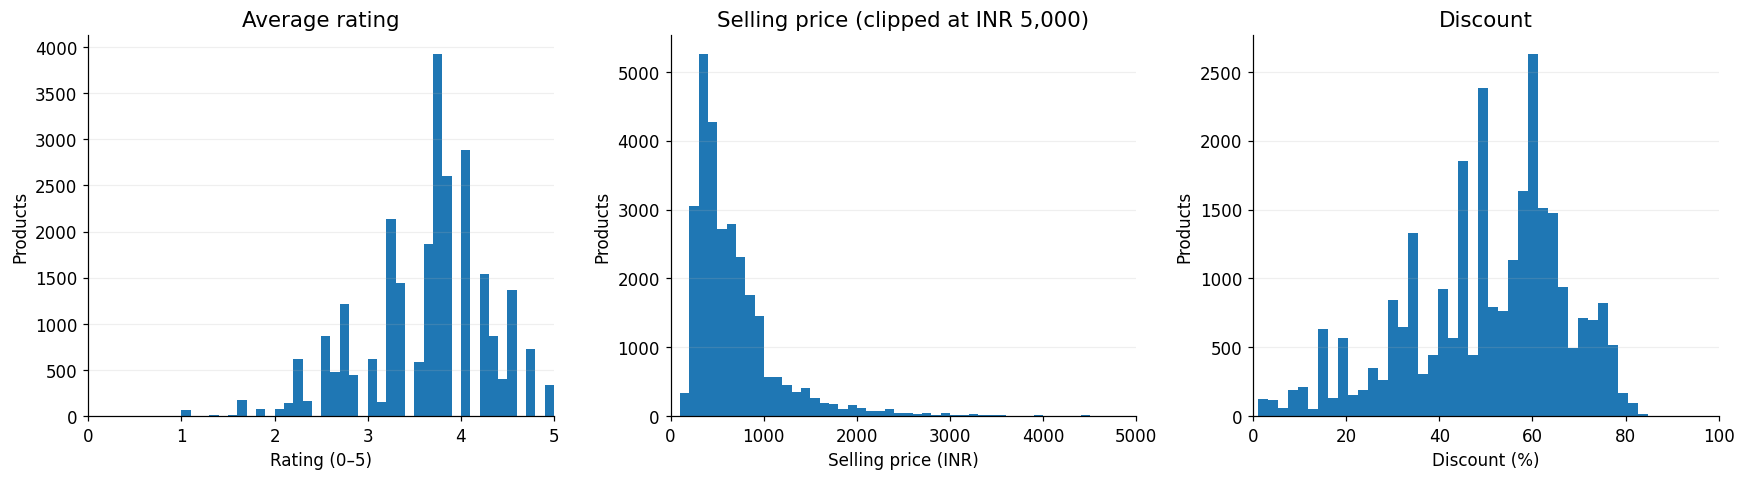

In [17]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
axes[0].hist(df["average_rating"].dropna(), bins=np.linspace(0, 5, 51), color="tab:blue")
axes[0].set(title="Average rating", xlabel="Rating (0–5)", ylabel="Products", xlim=(0, 5))

price_limit = 5000
visible_prices = df.loc[df["selling_price"].le(price_limit), "selling_price"].dropna()
axes[1].hist(visible_prices, bins=50, range=(0, price_limit), color="tab:blue")
axes[1].set(title="Selling price (clipped at INR 5,000)", xlabel="Selling price (INR)",
            ylabel="Products", xlim=(0, price_limit))

axes[2].hist(df["discount"].dropna(), bins=40, color="tab:blue")
axes[2].set(title="Discount", xlabel="Discount (%)", ylabel="Products", xlim=(0, 100))
for ax in axes:
    ax.grid(axis="y", alpha=0.2)
fig.tight_layout()
plt.show()

In [18]:
rating_summary = pd.Series({
    "Products rated 5.0": int(df["average_rating"].eq(5).sum()),
    "Products rated below 3.0": int(df["average_rating"].lt(3).sum()),
}, name="Products")
display(rating_summary.to_frame())

stock_counts = df["out_of_stock"].value_counts().reindex([False, True], fill_value=0)
stock_distribution = pd.DataFrame({
    "Products": stock_counts.values,
    "Share (%)": 100 * stock_counts.values / len(df),
}, index=pd.Index(["In stock", "Out of stock"], name="Stock status"))
display(stock_distribution.round(2))

print("Most expensive product:")
display(df.loc[[df["selling_price"].idxmax()],
               ["pid", "title", "selling_price", "actual_price", "average_rating"]])
print("Largest discount:")
display(df.loc[[df["discount"].idxmax()],
               ["pid", "title", "actual_price", "selling_price", "discount"]])

,Products
Products rated 5.0,329
Products rated below 3.0,4342


,Products,Share (%)
Stock status,,
In stock,26436,94.15
Out of stock,1644,5.85


Most expensive product:


,pid,title,selling_price,actual_price,average_rating
2067,TKTFZ3YGGMMNBYEZ,Solid Women Track Suit,7999.0,9999.0,2.7


Largest discount:


,pid,title,actual_price,selling_price,discount
906,TSHF5FRXKGF6A4FH,Printed Women Round Neck White T-Shirt,998.0,128.0,87.0


#### Most common brands and sellers


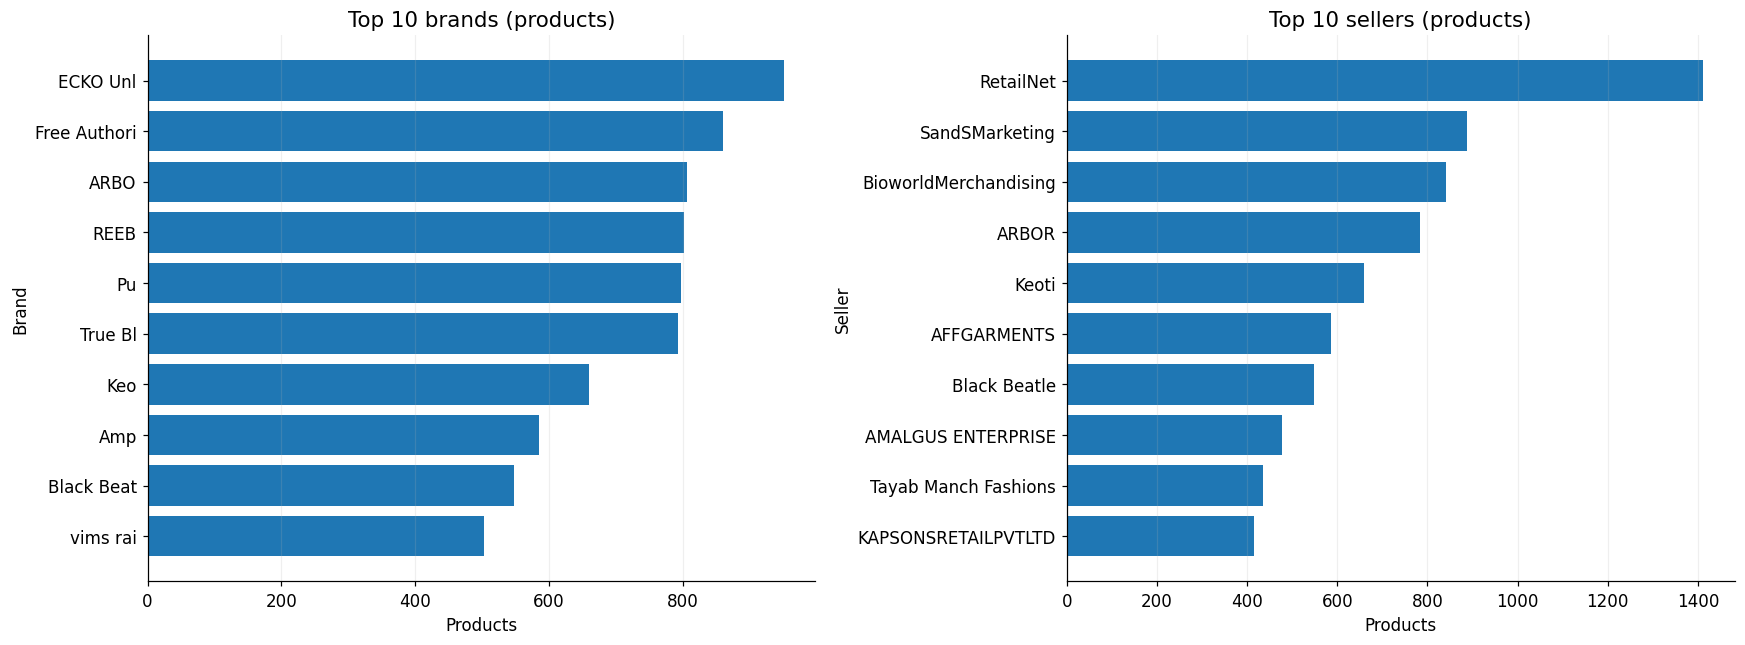

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
for column, ax in zip(("brand", "seller"), axes):
    names = df[column].str.strip()
    counts = names[names.ne("")].value_counts().head(10)
    ax.barh(counts.index[::-1], counts.values[::-1], color="tab:blue")
    ax.set(title=f"Top 10 {column}s (products)", xlabel="Products", ylabel=column.capitalize())
    ax.grid(axis="x", alpha=0.2)
fig.tight_layout()
plt.show()

In [ ]:
brand_ratings = (df.loc[df["brand"].str.strip().ne("")]
                 .groupby("brand").agg(
                     products=("pid", "size"),
                     mean_rating=("average_rating", "mean"),
                 ))
print("Best-rated brands with at least 100 products:")
display(brand_ratings.loc[brand_ratings["products"].ge(100)]
        .sort_values("mean_rating", ascending=False).head(10).round(2))

Best-rated brands with at least 100 products:


,products,mean_rating
brand,,
PixF,429,4.46
Cots,277,4.44
Zack Fo,128,4.33
Gracew,405,4.23
Marca Disa,353,4.19
Byford by Pantaloo,179,4.11
ARBO,806,4.10
TOM BU,290,4.10
Pu,798,4.06
